In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
DATA_PATH = Path('../src/clean_data.csv')
FS = 360

In [3]:
df = pd.read_csv(DATA_PATH)

signal_columns = sorted(
    [c for c in df.columns if c.startswith('x_')],
    key=lambda c: int(c.split('_')[1])
)

print(f'Liczba uderzeń: {len(df):,}')
print(f'Liczba rekordów: {df['record_id'].nunique()}')
print(f'Liczba próbek w segmencie: {len(signal_columns)}')
print(f'Czas segmentu: {len(signal_columns) / FS} s')

df.head()

Liczba uderzeń: 100,676
Liczba rekordów: 44
Liczba próbek w segmencie: 256
Czas segmentu: 0.7111111111111111 s


,record_id,annotation_sample,type,x_0,x_1,x_2,x_3,x_4,x_5,x_6,...,x_248,x_249,x_250,x_251,x_252,x_253,x_254,x_255,class,anomaly
0,100,370,N,-0.012063,-0.011870,-0.012323,-0.013667,-0.015435,-0.016664,-0.016444,...,0.031740,0.030491,0.028161,0.025477,0.023071,0.021232,0.019926,0.018956,N,0
1,100,662,N,-0.007641,-0.004494,-0.002241,-0.001259,-0.001613,-0.002982,-0.004748,...,-0.002470,-0.002016,-0.001907,-0.003053,-0.005780,-0.009739,-0.014134,-0.018067,N,0
2,100,946,N,-0.017088,-0.015658,-0.014706,-0.014649,-0.015687,-0.017712,-0.020420,...,0.016567,0.011699,0.007760,0.005607,0.005315,0.006294,0.007737,0.009020,N,0
3,100,1231,N,-0.015886,-0.012787,-0.010961,-0.011102,-0.013383,-0.017297,-0.021721,...,0.008601,0.006186,0.004477,0.003652,0.003842,0.004924,0.006367,0.007337,N,0
4,100,1515,N,0.006733,0.007868,0.007679,0.006301,0.004140,0.001740,-0.000411,...,0.021668,0.021216,0.020155,0.018518,0.016384,0.013742,0.010553,0.006958,N,0


In [15]:
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_n': df.isna().sum(),
    'missing_pct': 100 * df.isna().mean(),
    'unique_n': df.nunique(dropna=False)
})
summary.loc[['record_id', 'annotation_sample', 'type', 'anomaly', 'class']]

,dtype,missing_n,missing_pct,unique_n
record_id,int64,0,0.0,44
annotation_sample,int64,0,0.0,93508
type,str,0,0.0,12
anomaly,int64,0,0.0,2
class,str,0,0.0,4


### Sprawdzenie liczebności klas

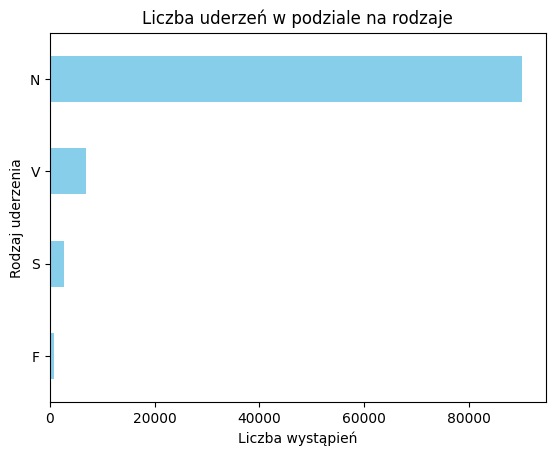

In [18]:
counts = df['class'].value_counts().sort_values()

counts.plot(kind='barh', color='skyblue')
plt.ylabel('Rodzaj uderzenia')
plt.xlabel('Liczba wystąpień')
plt.title('Liczba uderzeń w podziale na rodzaje')
plt.show()

In [19]:
type_distribution = pd.DataFrame({
    'count': counts,
    'pct': round(counts / len(df) * 100, 2)
}).sort_values(
    by='count',
    ascending=False
)
display(type_distribution)

,count,pct
class,,
N,90085,89.48
V,7008,6.96
S,2781,2.76
F,802,0.80


### Sprawdzenie liczebności anomalia vs. normalny

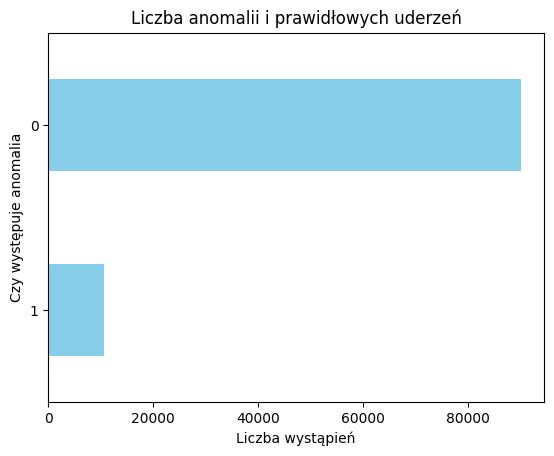

In [20]:
anomalies = df['anomaly'].value_counts().sort_values()

anomalies.plot(kind='barh', color='skyblue')
plt.ylabel('Czy występuje anomalia')
plt.xlabel('Liczba wystąpień')
plt.title('Liczba anomalii i prawidłowych uderzeń')
plt.show()

In [21]:
anomaly_pct = anomalies[1] / (anomalies[0]+anomalies[1]) * 100

print(f'Uderzenia anomalne stanowią {round(anomaly_pct,2)}% wszystkich uderzeń')

Uderzenia anomalne stanowią 10.52% wszystkich uderzeń


#### Sprawdzenie udziału uderzeń anomalnych per record_id

In [22]:
record_id_agg = (
    df.groupby('record_id')
    .agg(
        beats=('anomaly','size'),
        normal=('anomaly', lambda x: (x==0).sum()),
        anomaly=('anomaly', lambda x: (x==1).sum()),
    )
)
record_id_agg['anomaly_pct'] = round(record_id_agg['anomaly'] / record_id_agg['beats'] * 100, 2)

record_id_agg.sort_values('anomaly_pct', ascending=False)

,beats,normal,anomaly,anomaly_pct
record_id,,,,
232,1780,398,1382,77.64
208,2951,1585,1366,46.29
200,2600,1742,858,33.00
233,3077,2229,848,27.56
106,2027,1507,520,25.65
119,1987,1543,444,22.35
223,2604,2044,560,21.51
213,3249,2639,610,18.78
228,2053,1688,365,17.78


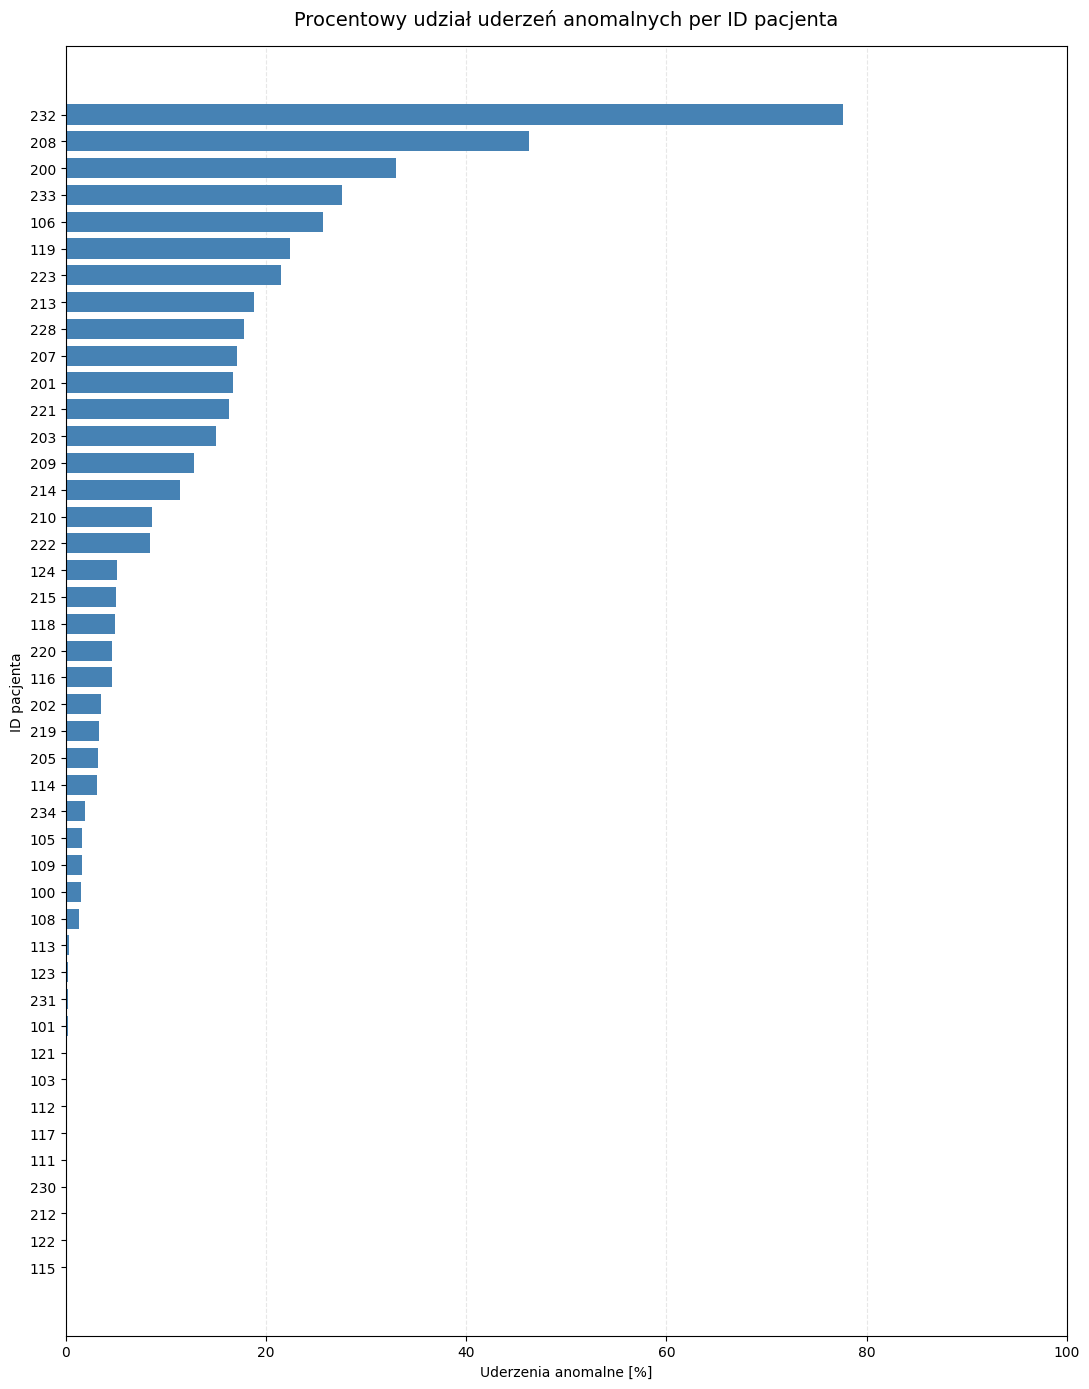

In [23]:
plot_data = record_id_agg.sort_values(
    by='anomaly_pct',
    ascending=True
)

fig, ax = plt.subplots(figsize=(11,14))

ax.barh(
    plot_data.index.astype(str),
    plot_data['anomaly_pct'],
    color='steelblue',
    height=0.75
)

ax.set_title(
    'Procentowy udział uderzeń anomalnych per ID pacjenta',
    fontsize=14,
    pad=15
)
ax.set_xlabel('Uderzenia anomalne [%]')
ax.set_ylabel('ID pacjenta')

ax.set_xlim(0,100)
ax.grid(axis='x',linestyle='--',alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Sprawdzenie liczby rekordów dla których występują dane typy uderzeń

In [24]:
df['record_id'].nunique()

44

In [25]:
record_id_agg = (
    df.groupby('type')
    .agg(
        beats_count=('type', 'size'),
        record_id_count=('record_id','nunique')
    )
    .sort_values(
        by='beats_count',
        ascending=False
    )
)
record_id_agg

,beats_count,record_id_count
type,,
N,74513,37
L,8072,4
R,7255,6
V,6902,33
A,2546,27
F,802,17
j,229,5
a,150,7
E,106,2


In [26]:
crosstab = pd.crosstab(df['record_id'], df['type'])
crosstab

type,A,E,F,J,L,N,R,S,V,a,e,j
record_id,,,,,,,,,,,,
100,33,0,0,0,0,2237,0,0,1,0,0,0
101,3,0,0,0,0,1859,0,0,0,0,0,0
103,2,0,0,0,0,2081,0,0,0,0,0,0
105,0,0,0,0,0,2526,0,0,41,0,0,0
106,0,0,0,0,0,1507,0,0,520,0,0,0
108,4,0,2,0,0,1738,0,0,17,0,0,1
109,0,0,2,0,2491,0,0,0,38,0,0,0
111,0,0,0,0,2123,0,0,0,1,0,0,0
112,2,0,0,0,0,2536,0,0,0,0,0,0


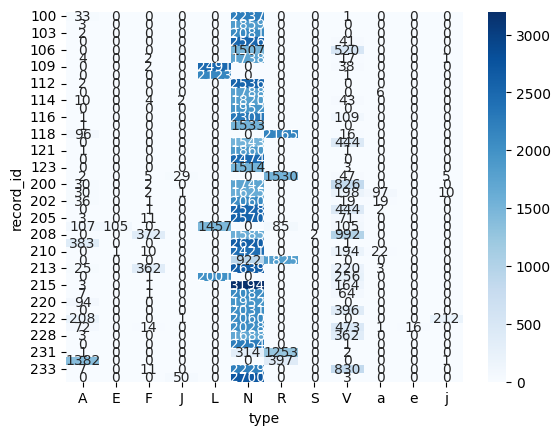

In [27]:
top_ids = crosstab.sum(axis=1).index

ct_top = crosstab.loc[top_ids]

sns.heatmap(
    ct_top,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.show()

In [4]:
class_per_record = pd.crosstab(
    df['record_id'],
    df['class']
)

class_per_record = class_per_record.reindex(
    columns=['N', 'S', 'V', 'F'],
    fill_value=0
)

display(class_per_record)

class,N,S,V,F
record_id,,,,
100,2237,33,1,0
101,1859,3,0,0
103,2081,2,0,0
105,2526,0,41,0
106,1507,0,520,0
108,1739,4,17,2
109,2491,0,38,2
111,2123,0,1,0
112,2536,2,0,0


In [5]:
print(
    "Liczba rekordów zawierających daną klasę:"
)

print(
    (class_per_record > 0).sum()
)

Liczba rekordów zawierających daną klasę:
class
N    44
S    32
V    33
F    17
dtype: int64
